# Bonus: can a fine-tuned small language model read reach from the text?

**Outside the course scope; an easter egg only.** The main notebook found that text and mood add little beyond author signals. Here we check whether a pretrained language model, fine-tuned on our tweets, finds signal in the words that bag-of-words missed.

- **Task:** predict `retweeted` (≥ 1 retweet) for an original tweet **from its text only**.
- **Model:** DistilBERT (`distilbert-base-uncased`, 66M parameters), fine-tuned for 2 epochs on Apple-silicon MPS (or CUDA/CPU).
- **Comparison:** TF-IDF + LogisticRegression on the same text, and the same user-grouped train/test split as `final_analysis.ipynb`.

Run `final_analysis.ipynb` first: it downloads the data and writes `results.json`. Extra packages: `torch`, `transformers`.

In [1]:
import json
import logging
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from huggingface_hub import hf_hub_download
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer

logging.basicConfig(stream=sys.stdout, level=logging.INFO, format="%(message)s", force=True)
log = logging.getLogger("moodreach.bonus")
sns.set_theme(style="whitegrid")
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
MODEL = "distilbert-base-uncased"
log.info("device: %s, model: %s", DEVICE, MODEL)


def save(name: str) -> None:
    plt.savefig(f"figures/{name}.png", dpi=120, bbox_inches="tight")
    log.info("saved figures/%s.png", name)

device: mps, model: distilbert-base-uncased


Same cleaning and split as the main notebook: dedupe TweetIDs, keep original tweets, cap at 20 tweets per user, split 80/20 by user.

In [2]:
path = hf_hub_download("haoxianc/paakhim10_tweets-and-engagement-metrics", "tweets-engagement-metrics.csv", repo_type="dataset", local_dir="data")
df = pd.read_csv(path, low_memory=False).drop(columns=["Unnamed: 0"]).drop_duplicates("TweetID").reset_index(drop=True)
df["text"] = df["text"].str.strip().str.strip('"').str.strip()
orig = df[~df.IsReshare].reset_index(drop=True)
rank = orig.assign(_r=np.random.default_rng(SEED).random(len(orig))).groupby("UserID")._r.rank(method="first")
orig = orig[rank <= 20].reset_index(drop=True)  # same ≤20-tweets-per-user cap as the main notebook
y = (orig.RetweetCount > 0).astype(int).to_numpy()
tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(orig, y, groups=orig.UserID))
main = json.load(open("results.json"))
assert len(orig) == main["data"]["capped_tweets"], "cleaning differs from final_analysis.ipynb"
log.info("train %d, test %d, positive rate %.3f", len(tr_idx), len(te_idx), y.mean())

HTTP Request: HEAD https://huggingface.co/datasets/haoxianc/paakhim10_tweets-and-engagement-metrics/resolve/main/tweets-engagement-metrics.csv "HTTP/1.1 302 Found"


train 39358, test 9464, positive rate 0.179


In [3]:
tfidf = TfidfVectorizer(min_df=3, ngram_range=(1, 2), max_features=50000)
T_tr, T_te = tfidf.fit_transform(orig.text.iloc[tr_idx]), tfidf.transform(orig.text.iloc[te_idx])
bow = LogisticRegression(max_iter=3000, C=1.0, class_weight="balanced").fit(T_tr, y[tr_idx])
p_bow = bow.predict_proba(T_te)[:, 1]
log.info("TF-IDF + LogisticRegression (text only): AUC=%.4f AP=%.4f", roc_auc_score(y[te_idx], p_bow), average_precision_score(y[te_idx], p_bow))

TF-IDF + LogisticRegression (text only): AUC=0.7329 AP=0.3700


### Fine-tune DistilBERT

The loss weights positives by the class ratio, mirroring `class_weight="balanced"`. Tweets are short, so 64 tokens covers almost all of them.

In [4]:
tok = AutoTokenizer.from_pretrained(MODEL)


def encode(texts: pd.Series) -> TensorDataset:
    enc = tok(list(texts), truncation=True, max_length=64, padding="max_length", return_tensors="pt")
    return TensorDataset(enc["input_ids"], enc["attention_mask"])


ds_tr = encode(orig.text.iloc[tr_idx])
ds_te = encode(orig.text.iloc[te_idx])
labels_tr = torch.tensor(y[tr_idx])
model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=2).to(DEVICE)
EPOCHS, BATCH, LR = 2, 64, 3e-5
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
steps = EPOCHS * int(np.ceil(len(tr_idx) / BATCH))
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=steps, pct_start=0.1)
pos_weight = (1 - y[tr_idx].mean()) / y[tr_idx].mean()
loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor([1.0, pos_weight], dtype=torch.float32, device=DEVICE))


@torch.no_grad()
def predict(ds: TensorDataset) -> np.ndarray:
    model.eval()
    out = []
    for ids, mask in DataLoader(ds, batch_size=256):
        logits = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE)).logits
        out.append(torch.softmax(logits, -1)[:, 1].float().cpu().numpy())
    return np.concatenate(out)


history = []
t0 = time.time()
step = 0
for epoch in range(EPOCHS):
    model.train()
    perm = torch.randperm(len(tr_idx))
    for b in range(0, len(perm), BATCH):
        i = perm[b : b + BATCH]
        ids, mask = ds_tr.tensors[0][i].to(DEVICE), ds_tr.tensors[1][i].to(DEVICE)
        loss = loss_fn(model(input_ids=ids, attention_mask=mask).logits, labels_tr[i].to(DEVICE))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        sched.step()
        opt.zero_grad()
        step += 1
        if step % 100 == 0:
            log.info("epoch %d step %d/%d loss %.4f (%.0fs)", epoch + 1, step, steps, loss.item(), time.time() - t0)
    p_llm = predict(ds_te)
    history.append({"epoch": epoch + 1, "test_AUC": roc_auc_score(y[te_idx], p_llm), "seconds": time.time() - t0})
    log.info("epoch %d: test AUC %.4f", epoch + 1, history[-1]["test_AUC"])
pd.DataFrame(history)

HTTP Request: GET https://huggingface.co/api/models/distilbert-base-uncased "HTTP/1.1 307 Temporary Redirect"


HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased "HTTP/1.1 200 OK"


HTTP Request: GET https://huggingface.co/api/models/distilbert-base-uncased/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 307 Temporary Redirect"


HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"


HTTP Request: GET https://huggingface.co/api/models/distilbert-base-uncased/tree/main?recursive=true&expand=false "HTTP/1.1 307 Temporary Redirect"


HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"


... (16 outputs left out)

epoch 2 step 1100/1230 loss 0.6452 (301s)


epoch 2 step 1200/1230 loss 0.6943 (326s)


epoch 2: test AUC 0.7588


,epoch,test_AUC,seconds
0,1,0.753811,173.605979
1,2,0.758764,343.874963


test ROC AUC, retweeted yes/no:
Mood features only (LogReg)       0.5240
Text: TF-IDF + LogReg             0.7329
Text: fine-tuned DistilBERT       0.7588
All metadata, no text (LogReg)    0.7230


saved figures/7_1_llm_bonus.png


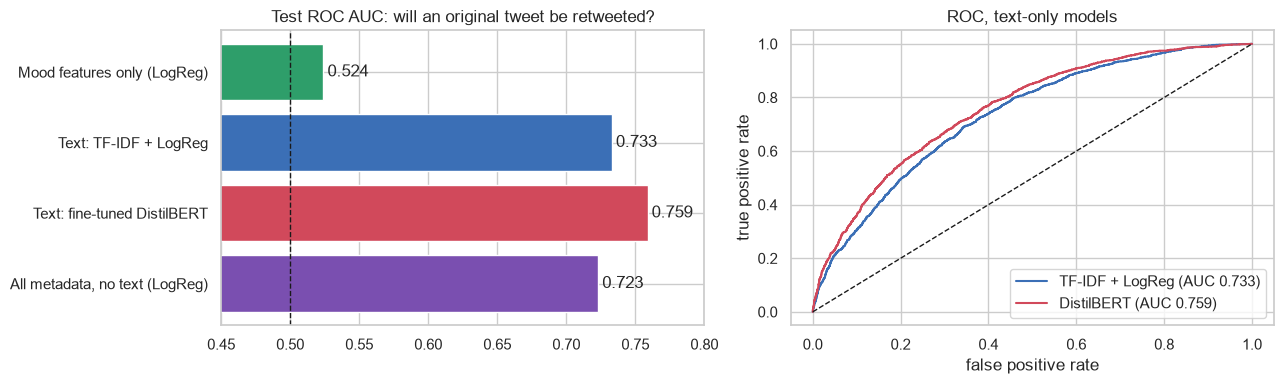

Mood features only (LogReg)       0.5240
Text: TF-IDF + LogReg             0.7329
Text: fine-tuned DistilBERT       0.7588
All metadata, no text (LogReg)    0.7230
dtype: float64

In [5]:
rows = {
    "Mood features only (LogReg)": next(r["ROC_AUC"] for r in main["logistic"]["table"] if r["model"] == "Mood features only"),
    "Text: TF-IDF + LogReg": roc_auc_score(y[te_idx], p_bow),
    "Text: fine-tuned DistilBERT": roc_auc_score(y[te_idx], p_llm),
    "All metadata, no text (LogReg)": next(r["ROC_AUC"] for r in main["logistic"]["table"] if r["model"] == "All features"),
}
auc = pd.Series(rows).round(4)
log.info("test ROC AUC, retweeted yes/no:\n%s", auc.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
colors = ["#2e9e6a", "#3b6fb6", "#d1495b", "#7a4fb0"]
axes[0].barh(auc.index[::-1], auc.values[::-1], color=colors[::-1])
axes[0].axvline(0.5, color="k", ls="--", lw=1)
axes[0].set_xlim(0.45, max(0.8, auc.max() + 0.03))
for i, v in enumerate(auc.values[::-1]):
    axes[0].text(v + 0.003, i, f"{v:.3f}", va="center")
axes[0].set_title("Test ROC AUC: will an original tweet be retweeted?")
for name, p, c in [("TF-IDF + LogReg", p_bow, "#3b6fb6"), ("DistilBERT", p_llm, "#d1495b")]:
    fpr, tpr, _ = roc_curve(y[te_idx], p)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y[te_idx], p):.3f})", color=c)
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_xlabel("false positive rate")
axes[1].set_ylabel("true positive rate")
axes[1].set_title("ROC, text-only models")
axes[1].legend()
plt.tight_layout()
save("7_1_llm_bonus")
plt.show()

json.dump(
    {"device": DEVICE, "model": MODEL, "epochs": EPOCHS, "train_seconds": round(history[-1]["seconds"], 1), "test_auc": auc.to_dict(), "history": history},
    open("bonus_results.json", "w"),
    indent=2,
)
auc

**Reading it:** text alone ranks tweets about as well as all the metadata: TF-IDF + LogReg reaches 0.73 and DistilBERT 0.76, against 0.72 for LogisticRegression on metadata. DistilBERT adds about +0.03 AUC over bag-of-words by reading phrasing and topic.

Much of that text signal still describes the **kind of account**, not the mood. Automated feeds ("via dlvr.it", job boards) rarely get retweeted, while event hashtags and official announcements do (see `figures/6_2_words_that_spread.png`). Mood alone stays near chance (0.52).

A fine-tuned transformer is hard to interpret and needs a GPU for minutes instead of a CPU for seconds, so the main analysis stays with linear models.